# Road Accident Severity Prediction Using Machine Learning

**Problem-Based Learning (PBL) | AIDS Department | Google Colab**

This notebook follows the PBL evaluation lifecycle: problem definition, dataset understanding, cleaning, EDA, feature engineering, model development, validation, interpretation, and recommendations.

> **Important scope clarification:** The supplied dataset contains records of accidents that have already occurred and a target named `Accident_Severity_C`. Therefore, this notebook predicts the **severity class of a recorded accident**. It does not predict whether an accident will occur. A true pre-crash risk prediction system would require a different target and suitable exposure/non-accident data.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from google.colab import files
from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload the dataset

In [2]:
print("Upload ETP_4_New_Data_Accidents.csv")
uploaded = files.upload()
if not uploaded:
    raise ValueError("No file was uploaded.")

file_name = next(iter(uploaded))
df_raw = pd.read_csv(file_name)
print("Uploaded file:", file_name)
print("Original dataset shape:", df_raw.shape)
display(df_raw.head())

Upload ETP_4_New_Data_Accidents.csv


Saving ETP_4_New_Data_Accidents.csv to ETP_4_New_Data_Accidents.csv
Uploaded file: ETP_4_New_Data_Accidents.csv
Original dataset shape: (8116, 13)


,Date,Day_of_Week,Time_of_Accident,Accident_Location_A,Accident_Location_A_Chainage_km,Accident_Location_A_Chainage_km_RoadSide,Accident_Severity_C,Causes_D,Road_Feature_E,Road_Condition_F,Weather_Conditions_H,Vehicle_Type_Involved_J_V1,Vehicle_Type_Involved_J_V2
0,1/9/2013,7,13:00,2,187.6,1,3,2,2,3,8,1,NaN
1,4/9/2013,3,15:25,2,152.3,2,4,3,2,6,12,5,NaN
2,9/9/2013,1,0:40,2,177.8,1,4,3,2,6,12,5,NaN
3,11/9/2013,3,7:30,2,186.8,2,3,2,2,3,8,1,NaN
4,17/09/2013,2,13:00,2,173.4,2,4,4,3,4,7,1,NaN


## 3. Problem definition and business understanding

**Problem:** Classify the severity of a recorded road accident using the accident information available in the dataset.

**Objective:** Build and validate a multi-class classification model that can support road-safety analysis and help authorities understand which recorded accident conditions are associated with different severity classes.

**Potential stakeholders:** Traffic police, highway/road authorities, emergency response teams, and road-safety planners.

**Potential KPIs:** Macro F1-score, per-class recall, balanced accuracy, confusion matrix, and the number of correctly identified records in each severity class.

**Scope limitation:** The model is an analytical decision-support prototype. It must not be treated as a live emergency or pre-crash warning system without prospective data, external validation, and a suitable operational study.

## 4. Dataset understanding and data dictionary

In [3]:
df = df_raw.copy()
df.columns = (
    df.columns.astype(str).str.strip().str.lower()
      .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_")
)

print("Rows and columns:", df.shape)
print("\nData types and non-null counts:")
df.info()
print("\nStatistical summary:")
display(df.describe(include="all").T)
print("\nMissing values:")
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing_summary)
print("\nUnique values per column:")
display(df.nunique(dropna=False).to_frame("unique_values"))

data_dictionary = pd.DataFrame({
    "column": df.columns,
    "data_type": [str(df[c].dtype) for c in df.columns],
    "non_null": [df[c].notna().sum() for c in df.columns],
    "unique_values": [df[c].nunique(dropna=True) for c in df.columns],
    "sample_values": [df[c].dropna().astype(str).unique()[:5].tolist() for c in df.columns]
})
display(data_dictionary)

Rows and columns: (8116, 13)

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8116 entries, 0 to 8115
Data columns (total 13 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   date                                      8116 non-null   object 
 1   day_of_week                               8116 non-null   int64  
 2   time_of_accident                          8116 non-null   object 
 3   accident_location_a                       8116 non-null   int64  
 4   accident_location_a_chainage_km           8116 non-null   float64
 5   accident_location_a_chainage_km_roadside  8116 non-null   int64  
 6   accident_severity_c                       8116 non-null   int64  
 7   causes_d                                  8116 non-null   int64  
 8   road_feature_e                            8116 non-null   int64  
 9   road_condition_f                          811

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,8116,1664,13/07/2022,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,8116.0,NaN,NaN,NaN,4.096106,1.989654,1.0,2.0,4.0,6.0,7.0
time_of_accident,8116,797,1:30,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN
accident_location_a,8116.0,NaN,NaN,NaN,1.864465,0.342315,1.0,2.0,2.0,2.0,2.0
accident_location_a_chainage_km,8116.0,NaN,NaN,NaN,317.597007,163.779091,0.2,185.2,247.0,481.2,741.395
accident_location_a_chainage_km_roadside,8116.0,NaN,NaN,NaN,1.506284,0.499991,1.0,1.0,2.0,2.0,2.0
accident_severity_c,8116.0,NaN,NaN,NaN,2.642188,0.86792,1.0,2.0,3.0,3.0,4.0
causes_d,8116.0,NaN,NaN,NaN,2.544357,0.825131,1.0,2.0,2.0,3.0,8.0
road_feature_e,8116.0,NaN,NaN,NaN,3.684327,0.743114,1.0,4.0,4.0,4.0,4.0
road_condition_f,8116.0,NaN,NaN,NaN,1.361262,0.987961,1.0,1.0,1.0,1.0,8.0



Missing values:


,missing_count,missing_percent
vehicle_type_involved_j_v2,6154,75.83
day_of_week,0,0.00
time_of_accident,0,0.00
accident_location_a,0,0.00
date,0,0.00
accident_location_a_chainage_km,0,0.00
accident_location_a_chainage_km_roadside,0,0.00
causes_d,0,0.00
accident_severity_c,0,0.00
road_feature_e,0,0.00



Unique values per column:


,unique_values
date,1664
day_of_week,7
time_of_accident,797
accident_location_a,2
accident_location_a_chainage_km,2569
accident_location_a_chainage_km_roadside,2
accident_severity_c,4
causes_d,7
road_feature_e,4
road_condition_f,8


,column,data_type,non_null,unique_values,sample_values
0,date,object,8116,1664,"[1/9/2013, 4/9/2013, 9/9/2013, 11/9/2013, 17/0..."
1,day_of_week,int64,8116,7,"[7, 3, 1, 2, 4]"
2,time_of_accident,object,8116,797,"[13:00, 15:25, 0:40, 7:30, 10:15]"
3,accident_location_a,int64,8116,2,"[2, 1]"
4,accident_location_a_chainage_km,float64,8116,2569,"[187.6, 152.3, 177.8, 186.8, 173.4]"
5,accident_location_a_chainage_km_roadside,int64,8116,2,"[1, 2]"
6,accident_severity_c,int64,8116,4,"[3, 4, 2, 1]"
7,causes_d,int64,8116,7,"[2, 3, 4, 1, 5]"
8,road_feature_e,int64,8116,4,"[2, 3, 4, 1]"
9,road_condition_f,int64,8116,8,"[3, 6, 4, 5, 7]"


### Interpreting coded fields

Several fields are represented by numeric codes (for example, `Causes_D`, `Road_Feature_E`, and `Weather_Conditions_H`). The supplied CSV does not include a codebook explaining what each code means. This notebook therefore treats these fields as **categories**, not continuous measurements, and does not invent descriptions for the codes. Add the official dataset codebook to the report if it is available.

## 5. Data quality checks and preprocessing

In [4]:
# Work on a copy. First quantify exact duplicate rows before deciding how to handle them.
duplicate_mask = df.duplicated(keep="first")
print("Exact duplicate rows detected:", int(duplicate_mask.sum()))
print("Duplicate percentage:", round(duplicate_mask.mean() * 100, 2), "%")

# Inspect how often complete row patterns occur.
row_frequency = df.groupby(list(df.columns), dropna=False).size()
print("\nFrequency of identical complete-row patterns:")
display(row_frequency.value_counts().sort_index().to_frame("number_of_patterns"))

# Exact duplicate rows are repeated copies of the same complete record.
# Retain one copy of each exact row; do not remove merely similar records.
before_dedup = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Rows before exact-deduplication:", before_dedup)
print("Rows after exact-deduplication:", len(df))
print("Exact duplicate rows removed:", before_dedup - len(df))

# Remove only fully empty columns and constant columns (if any).
empty_columns = df.columns[df.isna().all()].tolist()
df = df.drop(columns=empty_columns)

constant_columns = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]
df = df.drop(columns=constant_columns)

print("Removed fully empty columns:", empty_columns)
print("Removed constant columns:", constant_columns)
print("Cleaned dataset shape:", df.shape)
display(df.head())

Exact duplicate rows detected: 4063
Duplicate percentage: 50.06 %

Frequency of identical complete-row patterns:


,number_of_patterns
1,8
2,4037
4,7
6,1


Rows before exact-deduplication: 8116
Rows after exact-deduplication: 4053
Exact duplicate rows removed: 4063
Removed fully empty columns: []
Removed constant columns: []
Cleaned dataset shape: (4053, 13)


,date,day_of_week,time_of_accident,accident_location_a,accident_location_a_chainage_km,accident_location_a_chainage_km_roadside,accident_severity_c,causes_d,road_feature_e,road_condition_f,weather_conditions_h,vehicle_type_involved_j_v1,vehicle_type_involved_j_v2
0,1/9/2013,7,13:00,2,187.6,1,3,2,2,3,8,1,NaN
1,4/9/2013,3,15:25,2,152.3,2,4,3,2,6,12,5,NaN
2,9/9/2013,1,0:40,2,177.8,1,4,3,2,6,12,5,NaN
3,11/9/2013,3,7:30,2,186.8,2,3,2,2,3,8,1,NaN
4,17/09/2013,2,13:00,2,173.4,2,4,4,3,4,7,1,NaN


### Duplicate-handling decision

The dataset contains a large number of exact repeated rows. Exact copies do not add new information and can make evaluation appear more confident than it should. The notebook removes only rows that match across **all columns**. The frequency table above is retained as evidence. Confirm with the dataset provider whether these repetitions are accidental duplicates or an intentional sampling design before final submission.

## 6. Target definition and target distribution

Target: accident_severity_c
Problem type: Multi-class classification


,record_count
accident_severity_c,
1,352
2,1450
3,1542
4,709


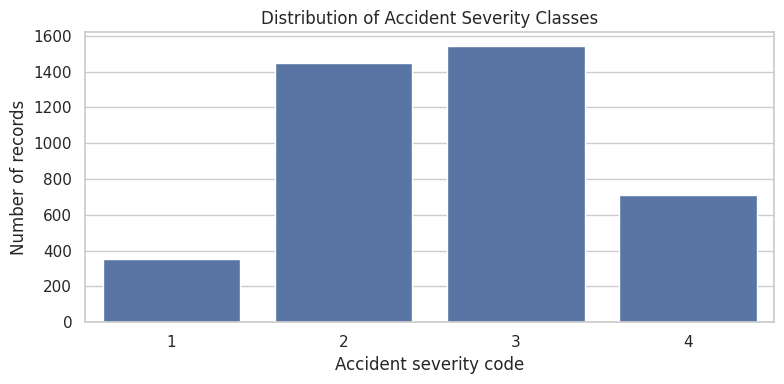

In [5]:
target_col = "accident_severity_c"
if target_col not in df.columns:
    raise ValueError(f"Target column '{target_col}' was not found.")

df = df.dropna(subset=[target_col]).copy()
y_raw = df[target_col].astype(str)
X = df.drop(columns=[target_col]).copy()

print("Target:", target_col)
print("Problem type: Multi-class classification")
target_counts = y_raw.value_counts().sort_index()
display(target_counts.to_frame("record_count"))

plt.figure(figsize=(8, 4))
sns.countplot(x=y_raw, order=target_counts.index)
plt.title("Distribution of Accident Severity Classes")
plt.xlabel("Accident severity code")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

## 7. Exploratory data analysis (EDA)

Unparsed date values: 0
Unparsed time values: 0


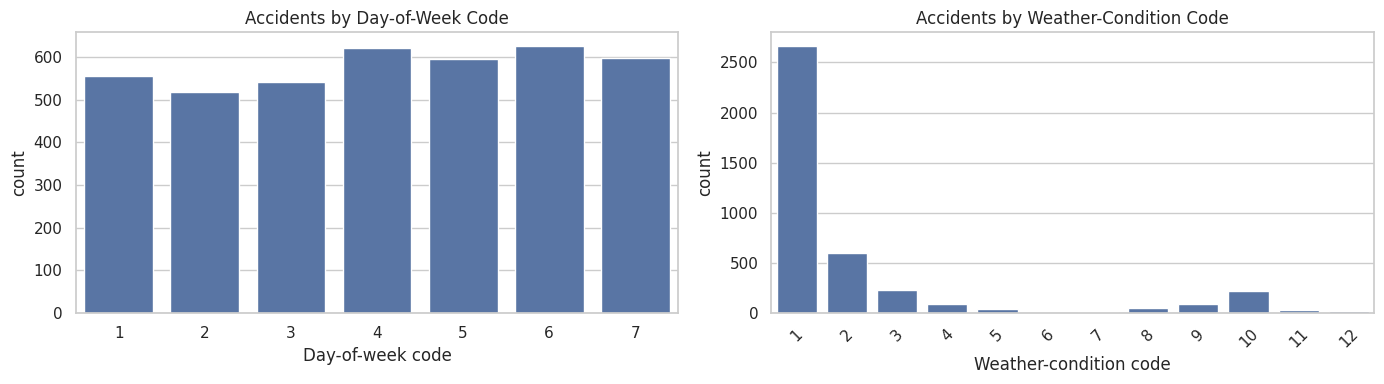

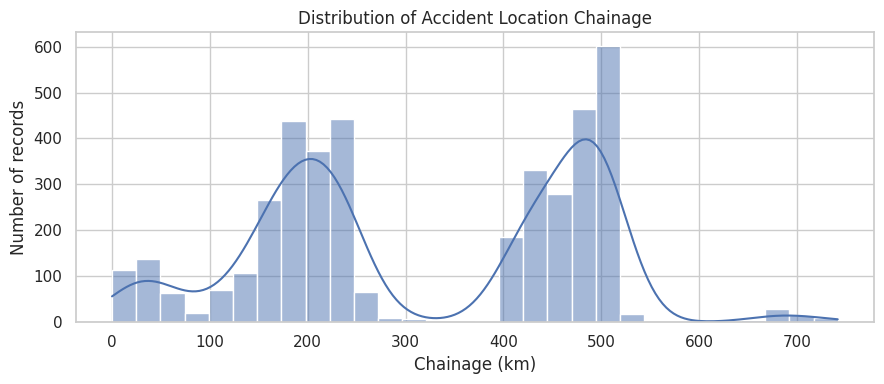

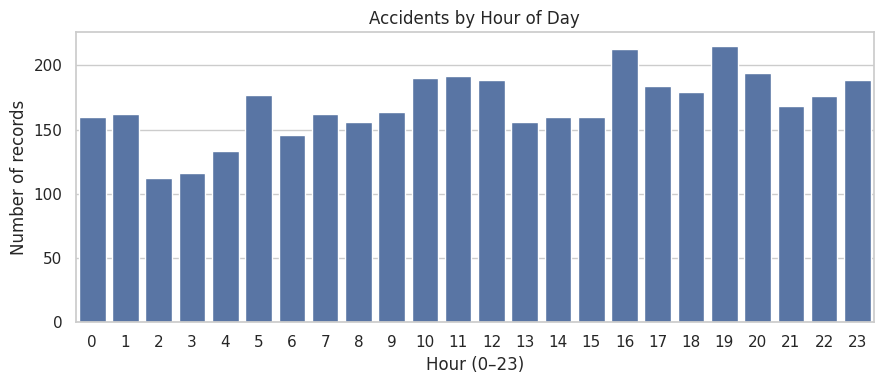

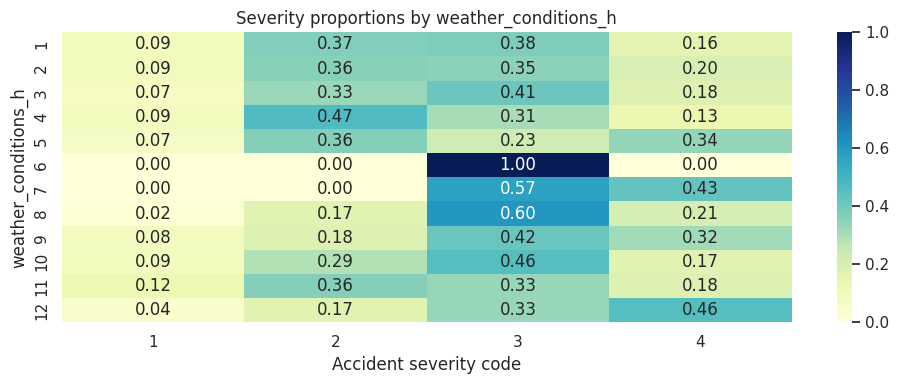

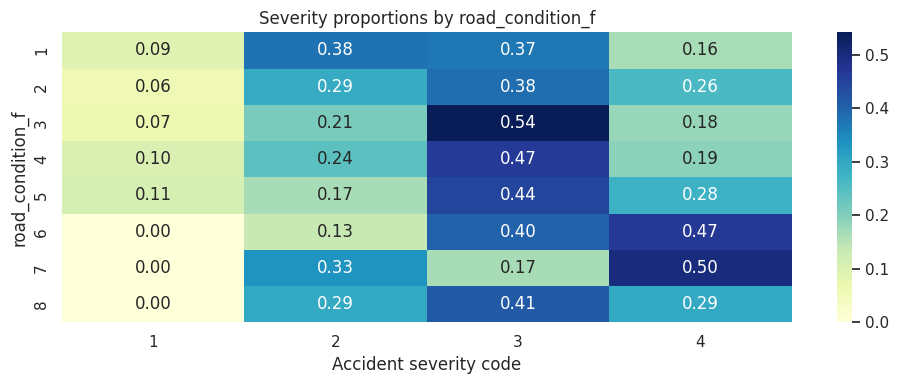

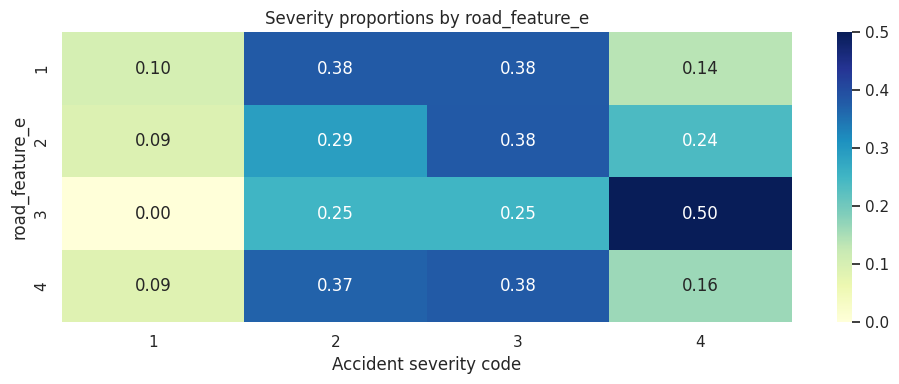

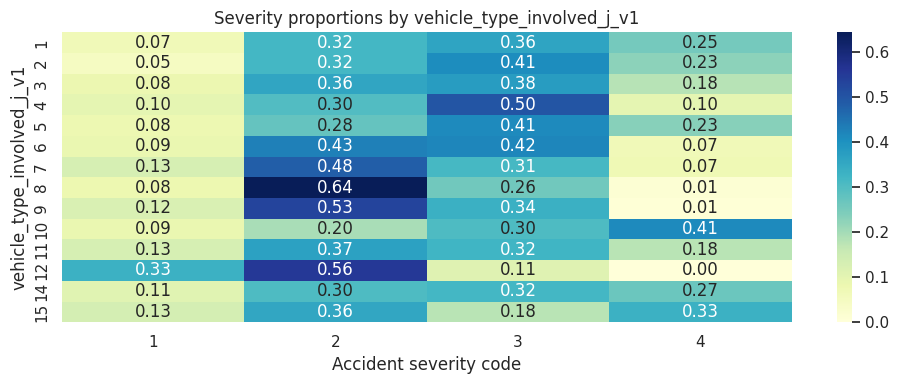

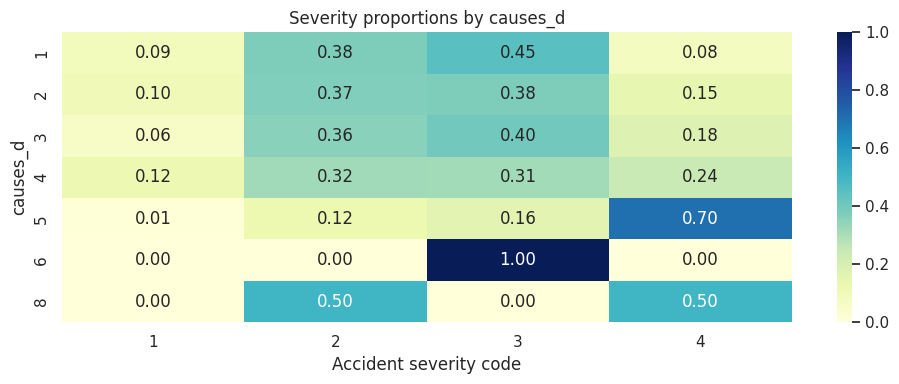

In [6]:
# Parse date/time for EDA. Invalid values are reported rather than silently hidden.
date_parsed = pd.to_datetime(X["date"], dayfirst=True, errors="coerce") if "date" in X else pd.Series(pd.NaT, index=X.index)
time_parsed = pd.to_datetime(X["time_of_accident"].astype(str), format="%H:%M", errors="coerce") if "time_of_accident" in X else pd.Series(pd.NaT, index=X.index)

print("Unparsed date values:", int(date_parsed.isna().sum()))
print("Unparsed time values:", int(time_parsed.isna().sum()))

eda_df = df.copy()
eda_df["accident_year_eda"] = date_parsed
eda_df["accident_hour_eda"] = time_parsed.dt.hour

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=eda_df, x="day_of_week", ax=axes[0])
axes[0].set_title("Accidents by Day-of-Week Code")
axes[0].set_xlabel("Day-of-week code")
sns.countplot(data=eda_df, x="weather_conditions_h", ax=axes[1])
axes[1].set_title("Accidents by Weather-Condition Code")
axes[1].set_xlabel("Weather-condition code")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
sns.histplot(df["accident_location_a_chainage_km"], bins=30, kde=True)
plt.title("Distribution of Accident Location Chainage")
plt.xlabel("Chainage (km)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

if eda_df["accident_hour_eda"].notna().any():
    plt.figure(figsize=(9, 4))
    sns.countplot(data=eda_df, x="accident_hour_eda")
    plt.title("Accidents by Hour of Day")
    plt.xlabel("Hour (0–23)")
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.show()

for feature in ["weather_conditions_h", "road_condition_f", "road_feature_e",
                "vehicle_type_involved_j_v1", "causes_d"]:
    if feature in df.columns:
        severity_table = pd.crosstab(df[feature], df[target_col], normalize="index")
        plt.figure(figsize=(10, 4))
        sns.heatmap(severity_table, annot=True, fmt=".2f", cmap="YlGnBu")
        plt.title(f"Severity proportions by {feature}")
        plt.xlabel("Accident severity code")
        plt.ylabel(feature)
        plt.tight_layout()
        plt.show()

### EDA interpretation prompt

After running the plots, write 2–4 evidence-based observations here. Mention the actual codes/categories and percentages visible in your outputs. Do not describe a code as “rain”, “highway”, “fatal”, etc. unless the official codebook confirms that meaning.

## 8. Statistical analysis and outlier assessment

,count,mean,std,min,25%,50%,75%,max
day_of_week,4053.0,4.099433,1.989417,1.0,2.0,4.0,6.0,7.000
accident_location_a,4053.0,1.864545,0.342251,1.0,2.0,2.0,2.0,2.000
accident_location_a_chainage_km,4053.0,317.503891,163.776636,0.2,185.2,246.8,481.2,741.395
accident_location_a_chainage_km_roadside,4053.0,1.505798,0.500028,1.0,1.0,2.0,2.0,2.000
causes_d,4053.0,2.544288,0.826107,1.0,2.0,2.0,3.0,8.000
road_feature_e,4053.0,3.683938,0.743535,1.0,4.0,4.0,4.0,4.000
road_condition_f,4053.0,1.361954,0.988584,1.0,1.0,1.0,1.0,8.000
weather_conditions_h,4053.0,2.279793,2.666504,1.0,1.0,1.0,2.0,12.000
vehicle_type_involved_j_v1,4053.0,5.415988,3.327940,1.0,3.0,5.0,6.0,15.000
vehicle_type_involved_j_v2,978.0,5.576687,3.567559,1.0,3.0,5.0,6.0,15.000


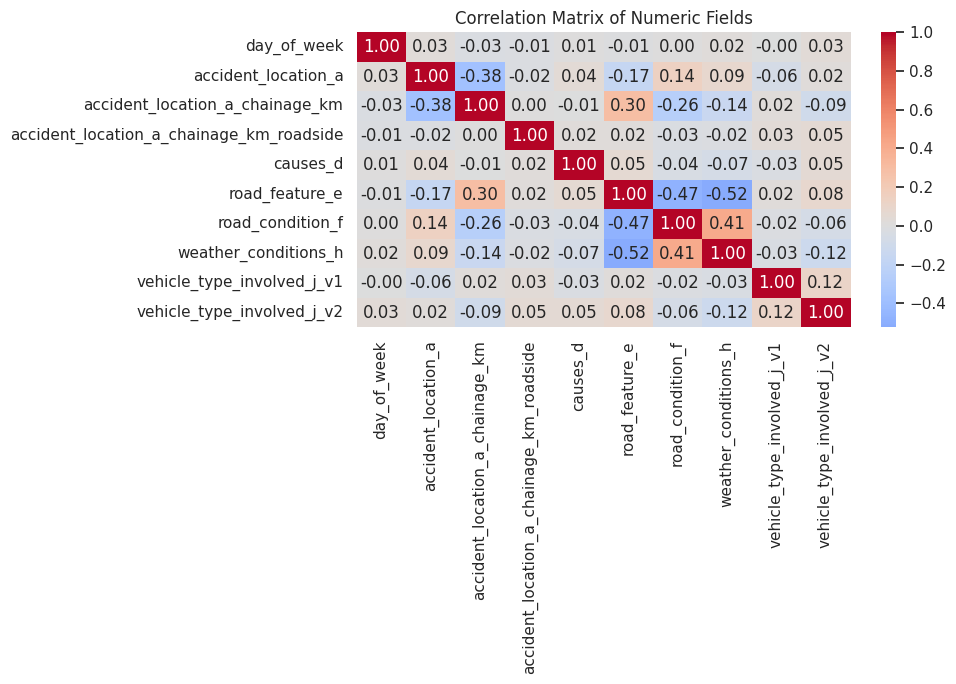

day_of_week: IQR lower=-4.000, upper=12.000, flagged=0
accident_location_a: IQR lower=2.000, upper=2.000, flagged=549
accident_location_a_chainage_km: IQR lower=-258.800, upper=925.200, flagged=0
accident_location_a_chainage_km_roadside: IQR lower=-0.500, upper=3.500, flagged=0
causes_d: IQR lower=0.500, upper=4.500, flagged=91
road_feature_e: IQR lower=4.000, upper=4.000, flagged=628
road_condition_f: IQR lower=1.000, upper=1.000, flagged=659
weather_conditions_h: IQR lower=-0.500, upper=3.500, flagged=559
vehicle_type_involved_j_v1: IQR lower=-1.500, upper=10.500, flagged=497
vehicle_type_involved_j_v2: IQR lower=-1.500, upper=10.500, flagged=108


In [7]:
# Numerical columns are reviewed separately. Coded category columns are excluded
# from numerical correlation/outlier interpretation.
numeric_cols_eda = df.select_dtypes(include=np.number).columns.tolist()
numeric_cols_eda = [c for c in numeric_cols_eda if c != target_col]

if numeric_cols_eda:
    display(df[numeric_cols_eda].describe().T)

    if len(numeric_cols_eda) >= 2:
        plt.figure(figsize=(10, 7))
        sns.heatmap(df[numeric_cols_eda].corr(numeric_only=True), annot=True,
                    cmap="coolwarm", center=0, fmt=".2f")
        plt.title("Correlation Matrix of Numeric Fields")
        plt.tight_layout()
        plt.show()

# IQR flags are diagnostic only. Do not automatically delete unusual chainage
# values because they may represent genuine accident locations.
for col in numeric_cols_eda:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((df[col] < lower) | (df[col] > upper)).sum())
    print(f"{col}: IQR lower={lower:.3f}, upper={upper:.3f}, flagged={count}")

## 9. Feature engineering

In [8]:
# Separate target and predictors already performed above.
# Create time-derived features and remove the original text date/time fields.
if "date" in X.columns:
    parsed_date = pd.to_datetime(X["date"], dayfirst=True, errors="coerce")
    X["accident_year"] = parsed_date.dt.year
    X["accident_month"] = parsed_date.dt.month
    X["accident_day"] = parsed_date.dt.day
    X.drop(columns=["date"], inplace=True)

if "time_of_accident" in X.columns:
    parsed_time = pd.to_datetime(X["time_of_accident"].astype(str),
                                 format="%H:%M", errors="coerce")
    X["accident_hour"] = parsed_time.dt.hour
    X["accident_minute"] = parsed_time.dt.minute
    X.drop(columns=["time_of_accident"], inplace=True)

# These fields are numeric codes, not continuous quantities.
coded_categorical = [
    "day_of_week", "accident_location_a",
    "accident_location_a_chainage_km_roadside", "causes_d",
    "road_feature_e", "road_condition_f", "weather_conditions_h",
    "vehicle_type_involved_j_v1", "vehicle_type_involved_j_v2"
]
for col in coded_categorical:
    if col in X.columns:
        X[col] = X[col].map(lambda v: str(v) if pd.notna(v) else np.nan)

print("Engineered feature columns:")
print(X.columns.tolist())
display(X.head())

Engineered feature columns:
['day_of_week', 'accident_location_a', 'accident_location_a_chainage_km', 'accident_location_a_chainage_km_roadside', 'causes_d', 'road_feature_e', 'road_condition_f', 'weather_conditions_h', 'vehicle_type_involved_j_v1', 'vehicle_type_involved_j_v2', 'accident_year', 'accident_month', 'accident_day', 'accident_hour', 'accident_minute']


,day_of_week,accident_location_a,accident_location_a_chainage_km,accident_location_a_chainage_km_roadside,causes_d,road_feature_e,road_condition_f,weather_conditions_h,vehicle_type_involved_j_v1,vehicle_type_involved_j_v2,accident_year,accident_month,accident_day,accident_hour,accident_minute
0,7,2,187.6,1,2,2,3,8,1,NaN,2013,9,1,13,0
1,3,2,152.3,2,3,2,6,12,5,NaN,2013,9,4,15,25
2,1,2,177.8,1,3,2,6,12,5,NaN,2013,9,9,0,40
3,3,2,186.8,2,2,2,3,8,1,NaN,2013,9,11,7,30
4,2,2,173.4,2,4,3,4,7,1,NaN,2013,9,17,13,0


### Feature availability / leakage note

The dataset describes completed accident records. Fields such as recorded cause and vehicle involvement may only be confirmed after an incident. They are acceptable for retrospective severity analysis only if they are genuinely available at the intended prediction time. For a real-time pre-crash model, exclude any field that is not known before the prediction and collect appropriate traffic/exposure data.

## 10. Feature selection and data split

In [9]:
# Remove columns that are identifiers only, if present.
possible_id_cols = [c for c in X.columns if c in
                    ["id", "accident_id", "record_id", "index"] or c.endswith("_id")]
if possible_id_cols:
    X = X.drop(columns=possible_id_cols)

# Ensure no accidental target copy remains in predictors.
X = X.drop(columns=[c for c in X.columns if c == target_col], errors="ignore")

# Encode target labels.
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw.astype(str))

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Number of predictors:", X.shape[1])
print("Target classes:", list(label_encoder.classes_))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training set:", X_train.shape, "Testing set:", X_test.shape)

Numeric features: ['accident_location_a_chainage_km', 'accident_year', 'accident_month', 'accident_day', 'accident_hour', 'accident_minute']
Categorical features: ['day_of_week', 'accident_location_a', 'accident_location_a_chainage_km_roadside', 'causes_d', 'road_feature_e', 'road_condition_f', 'weather_conditions_h', 'vehicle_type_involved_j_v1', 'vehicle_type_involved_j_v2']
Number of predictors: 15
Target classes: ['1', '2', '3', '4']
Training set: (3242, 15) Testing set: (811, 15)


## 11. Preprocessing pipeline

In [10]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Not recorded")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created.")
print("Imputation, scaling and encoding are fitted inside each training fold to reduce leakage.")

Preprocessing pipeline created.
Imputation, scaling and encoding are fitted inside each training fold to reduce leakage.


## 12. Baseline and model selection

In [12]:
models = {
    "Dummy Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=250, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": "f1_macro",
    "weighted_f1": "f1_weighted"
}

model_results = []
fitted_pipelines = {}

for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    cv_result = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=-1, return_train_score=False
    )
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe
    test_pred = pipe.predict(X_test)

    model_results.append({
        "Model": name,
        "CV Macro F1": cv_result["test_macro_f1"].mean(),
        "CV Macro F1 Std": cv_result["test_macro_f1"].std(),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "Test Macro F1": f1_score(y_test, test_pred, average="macro", zero_division=0),
        "Test Weighted F1": f1_score(y_test, test_pred, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(model_results).sort_values("CV Macro F1", ascending=False)
display(results_df.round(4))

,Model,CV Macro F1,CV Macro F1 Std,Test Accuracy,Test Balanced Accuracy,Test Macro F1,Test Weighted F1
2,Random Forest,0.3422,0.0106,0.4809,0.3796,0.3842,0.4605
3,Extra Trees,0.3405,0.0143,0.4451,0.3599,0.3647,0.4322
1,Logistic Regression,0.3171,0.0128,0.3637,0.3997,0.3424,0.3631
0,Dummy Baseline,0.1378,0.0003,0.3810,0.2500,0.1379,0.2102


## 13. Hyperparameter tuning

In [13]:
# Tune Random Forest using training data only. The held-out test set is not used
# for parameter selection.
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ))
])

param_distributions = {
    "model__n_estimators": [200, 300, 400],
    "model__max_depth": [None, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="f1_macro",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)
search.fit(X_train, y_train)

tuned_model = search.best_estimator_
print("Best CV Macro F1:", round(search.best_score_, 4))
print("Best parameters:")
print(search.best_params_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best CV Macro F1: 0.3879
Best parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': 'log2', 'model__max_depth': 15}


## 14. Final model selection and test evaluation

In [14]:
# Compare the tuned model against the best untuned candidate by training CV score.
best_untuned_name = results_df.loc[
    results_df["Model"] != "Dummy Baseline", "Model"
].iloc[0]
best_untuned_cv = results_df.loc[
    results_df["Model"] == best_untuned_name, "CV Macro F1"
].iloc[0]

if search.best_score_ >= best_untuned_cv:
    best_model = tuned_model
    best_model_name = "Tuned Random Forest"
else:
    best_model = fitted_pipelines[best_untuned_name]
    best_model_name = best_untuned_name

y_pred = best_model.predict(X_test)
print("Selected model:", best_model_name)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4))
print("Weighted F1:", round(f1_score(y_test, y_pred, average="weighted", zero_division=0), 4))

Selected model: Tuned Random Forest
Accuracy: 0.4538
Balanced accuracy: 0.4184
Macro F1: 0.3965
Weighted F1: 0.4489


## 15. Classification report and confusion matrix

              precision    recall  f1-score   support

           1       0.19      0.13      0.15        70
           2       0.54      0.48      0.50       290
           3       0.49      0.41      0.45       309
           4       0.38      0.65      0.48       142

    accuracy                           0.45       811
   macro avg       0.40      0.42      0.40       811
weighted avg       0.46      0.45      0.45       811



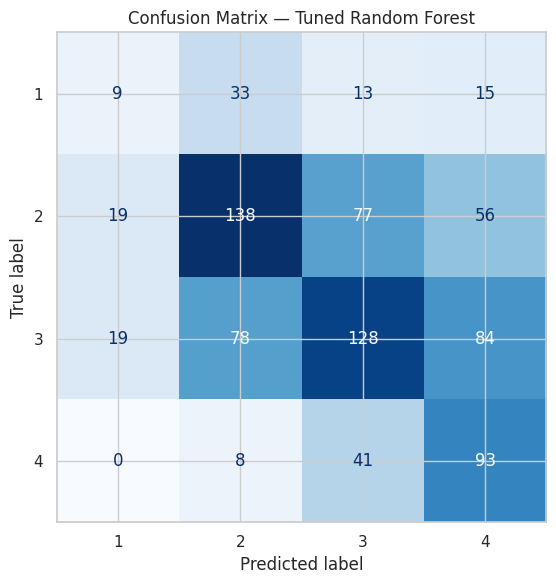

,Severity class,Recall
0,1,0.128571
1,2,0.475862
2,3,0.414239
3,4,0.654930


In [15]:
print(classification_report(
    y_test, y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(label_encoder.classes_)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

per_class_recall = recall_score(
    y_test, y_pred, average=None,
    labels=np.arange(len(label_encoder.classes_)), zero_division=0
)
class_metrics = pd.DataFrame({
    "Severity class": label_encoder.classes_,
    "Recall": per_class_recall
})
display(class_metrics)

## 16. Feature importance / model interpretation

,Feature,Importance_Mean,Importance_Std
8,vehicle_type_involved_j_v1,0.058931,0.009699
2,accident_location_a_chainage_km,0.049999,0.005357
10,accident_year,0.017080,0.006013
9,vehicle_type_involved_j_v2,0.014109,0.010666
5,road_feature_e,0.012643,0.003129
14,accident_minute,0.012224,0.004000
4,causes_d,0.010236,0.010141
13,accident_hour,0.005711,0.007511
3,accident_location_a_chainage_km_roadside,0.005237,0.002907
7,weather_conditions_h,0.004962,0.003511


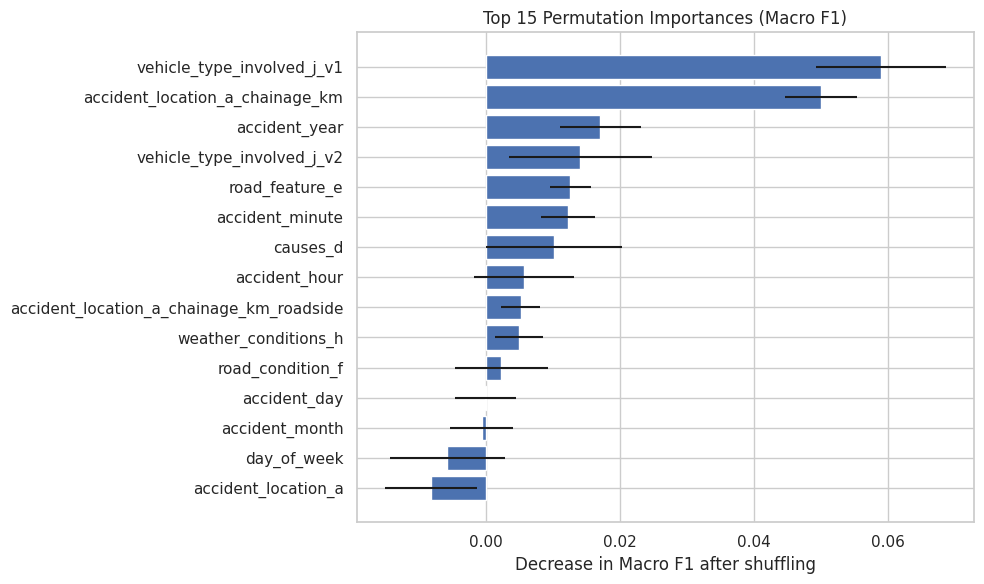

In [16]:
# Permutation importance is calculated on the held-out test set.
# It measures the reduction in macro F1 after shuffling each original input feature.
perm = permutation_importance(
    best_model, X_test, y_test,
    scoring="f1_macro", n_repeats=5,
    random_state=RANDOM_STATE, n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std
}).sort_values("Importance_Mean", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(10, 6))
top_features = importance_df.head(15).sort_values("Importance_Mean")
plt.barh(top_features["Feature"], top_features["Importance_Mean"],
         xerr=top_features["Importance_Std"])
plt.title("Top 15 Permutation Importances (Macro F1)")
plt.xlabel("Decrease in Macro F1 after shuffling")
plt.tight_layout()
plt.show()

## 17. Business insights and recommendations

In [17]:
print("OBSERVED TEST-SET PERFORMANCE")
print("Selected model:", best_model_name)
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))

print("\nClass-wise recall:")
for label, score in zip(label_encoder.classes_, per_class_recall):
    print(f"Severity class {label}: {score:.3f}")

print("\nTop model-associated features:")
display(importance_df.head(10))

print("\nRecommendations to consider after reviewing the actual EDA outputs:")
print("1. Investigate road/weather/time categories that show higher severe-class proportions.")
print("2. Prioritize locations only when the location analysis shows a repeated concentration.")
print("3. Review the lowest-recall severity class; do not rely on overall accuracy alone.")
print("4. Improve the completeness and consistency of accident and vehicle records.")
print("5. Validate the model on newer data and monitor class-wise performance before operational use.")

OBSERVED TEST-SET PERFORMANCE
Selected model: Tuned Random Forest
Macro F1: 0.3965
Balanced accuracy: 0.4184

Class-wise recall:
Severity class 1: 0.129
Severity class 2: 0.476
Severity class 3: 0.414
Severity class 4: 0.655

Top model-associated features:


,Feature,Importance_Mean,Importance_Std
8,vehicle_type_involved_j_v1,0.058931,0.009699
2,accident_location_a_chainage_km,0.049999,0.005357
10,accident_year,0.017080,0.006013
9,vehicle_type_involved_j_v2,0.014109,0.010666
5,road_feature_e,0.012643,0.003129
14,accident_minute,0.012224,0.004000
4,causes_d,0.010236,0.010141
13,accident_hour,0.005711,0.007511
3,accident_location_a_chainage_km_roadside,0.005237,0.002907
7,weather_conditions_h,0.004962,0.003511



Recommendations to consider after reviewing the actual EDA outputs:
1. Investigate road/weather/time categories that show higher severe-class proportions.
2. Prioritize locations only when the location analysis shows a repeated concentration.
3. Review the lowest-recall severity class; do not rely on overall accuracy alone.
4. Improve the completeness and consistency of accident and vehicle records.
5. Validate the model on newer data and monitor class-wise performance before operational use.


### Write your evidence-based business findings

Replace this note with 3–5 findings supported by your actual outputs. For each finding, include the relevant category/code, count or percentage, and a practical recommendation. Do not claim that a feature causes severe accidents based only on association or model importance.

## 18. Example prediction

In [18]:
# Use a real row from the test set as a demonstration input.
# This avoids asking for arbitrary category codes that may not exist in the dataset.
example_record = X_test.iloc[[0]].copy()
example_prediction = best_model.predict(example_record)
predicted_severity = label_encoder.inverse_transform(example_prediction)[0]

print("Example input record:")
display(example_record)
print("Predicted severity class:", predicted_severity)

if hasattr(best_model, "predict_proba"):
    probabilities = best_model.predict_proba(example_record)[0]
    probability_table = pd.DataFrame({
        "Severity class": label_encoder.classes_,
        "Predicted probability": probabilities
    }).sort_values("Predicted probability", ascending=False)
    display(probability_table)

Example input record:


,day_of_week,accident_location_a,accident_location_a_chainage_km,accident_location_a_chainage_km_roadside,causes_d,road_feature_e,road_condition_f,weather_conditions_h,vehicle_type_involved_j_v1,vehicle_type_involved_j_v2,accident_year,accident_month,accident_day,accident_hour,accident_minute
2842,6,2,500.1,1,4,4,1,1,5,NaN,2017,6,10,6,45


Predicted severity class: 3


,Severity class,Predicted probability
2,3,0.295868
3,4,0.283611
1,2,0.214726
0,1,0.205795


## 19. Limitations and future scope

**Limitations**
- The dataset contains only recorded accidents; it cannot estimate accident occurrence risk.
- Several variables are coded, and an official codebook was not supplied with the CSV.
- The second vehicle field has substantial missingness; its meaning and missingness mechanism should be confirmed.
- Exact duplicate rows were removed, but the source owner should confirm why repeated records exist.
- The model's performance may be affected by class imbalance and limited sample size.
- Retrospective test performance does not guarantee performance on future locations or years.

**Future scope**
- Obtain the official codebook and validate all category meanings.
- Validate on a later time period or an external dataset.
- Collect traffic volume, road exposure, speed, lighting, and other pre-event variables for genuine risk forecasting.
- Evaluate class-specific costs with road-safety stakeholders.
- Deploy only after independent validation, monitoring, and human review.

## 20. Final project summary

In [19]:
print("=" * 60)
print("ROAD ACCIDENT SEVERITY PREDICTION — FINAL SUMMARY")
print("=" * 60)
print("Dataset file:", file_name)
print("Cleaned records:", len(df))
print("Predictor count:", X.shape[1])
print("Target:", target_col)
print("Target classes:", list(label_encoder.classes_))
print("Selected model:", best_model_name)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Test balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
print("Test macro F1:", round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4))
print("Test weighted F1:", round(f1_score(y_test, y_pred, average="weighted", zero_division=0), 4))
print("\nProject lifecycle completed: understanding, cleaning, EDA, feature engineering,")
print("training, cross-validation, tuning, evaluation, interpretation and recommendations.")

ROAD ACCIDENT SEVERITY PREDICTION — FINAL SUMMARY
Dataset file: ETP_4_New_Data_Accidents.csv
Cleaned records: 4053
Predictor count: 15
Target: accident_severity_c
Target classes: ['1', '2', '3', '4']
Selected model: Tuned Random Forest
Test accuracy: 0.4538
Test balanced accuracy: 0.4184
Test macro F1: 0.3965
Test weighted F1: 0.4489

Project lifecycle completed: understanding, cleaning, EDA, feature engineering,
training, cross-validation, tuning, evaluation, interpretation and recommendations.


## Submission checklist

Before submitting:
1. Run **Runtime → Run all** in Google Colab from top to bottom.
2. Confirm every cell runs without an error.
3. Save the notebook with outputs visible.
4. Add the official codebook or explain that coded labels were not provided.
5. Write actual observations under the EDA and business-insights sections.
6. Explain duplicate handling and the high missingness in `Vehicle_Type_Involved_J_V2`.
7. Use the title **Road Accident Severity Prediction** consistently in the notebook, report, and PPT.

**Academic integrity:** Be prepared to explain every preprocessing choice, model, metric, chart, and limitation during your viva.